In [ ]:
#Solving CM using ANN

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
#Loading the Dataset
df = pd.read_csv('CM.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
#Selection iput and ouput
x=df.iloc[:,3:-1]
y=df.iloc[:,-1]
print(x.head())
print(y.head())
print(x.dtypes)

   CreditScore Geography  Gender  ...  HasCrCard  IsActiveMember  EstimatedSalary
0          619    France  Female  ...          1               1        101348.88
1          608     Spain  Female  ...          0               1        112542.58
2          502    France  Female  ...          1               0        113931.57
3          699    France  Female  ...          0               0         93826.63
4          850     Spain  Female  ...          1               1         79084.10

[5 rows x 10 columns]
0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
dtype: object


In [ ]:
# Data preprocessing
from sklearn.preprocessing import LabelEncoder
gender_encoder=LabelEncoder()
geography_encoder=LabelEncoder()
x ['Geography']=gender_encoder.fit_transform(x ['Geography'])
x ['Gender']=gender_encoder.fit_transform(x ['Gender'])
print(x.head())

   CreditScore  Geography  Gender  ...  HasCrCard  IsActiveMember  EstimatedSalary
0          619          0       0  ...          1               1        101348.88
1          608          2       0  ...          0               1        112542.58
2          502          0       0  ...          1               0        113931.57
3          699          0       0  ...          0               0         93826.63
4          850          2       0  ...          1               1         79084.10

[5 rows x 10 columns]


In [ ]:
#Train Test Split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 10)
(2000, 10)
(8000,)
(2000,)


In [ ]:
#Feature Scaling
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)
print(x_train)
print(x_test)

[[ 0.35649971 -0.9055496   0.91324755 ...  0.64920267  0.97481699
   1.36766974]
 [-0.20389777  0.30164867  0.91324755 ...  0.64920267  0.97481699
   1.6612541 ]
 [-0.96147213  1.50884694  0.91324755 ...  0.64920267 -1.02583358
  -0.25280688]
 ...
 [ 0.86500853 -0.9055496  -1.09499335 ... -1.54035103 -1.02583358
  -0.1427649 ]
 [ 0.15932282 -0.9055496   0.91324755 ...  0.64920267 -1.02583358
  -0.05082558]
 [ 0.47065475  0.30164867  0.91324755 ...  0.64920267  0.97481699
  -0.81456811]]
[[-0.57749609  0.30164867  0.91324755 ... -1.54035103 -1.02583358
  -1.01960511]
 [-0.29729735 -0.9055496   0.91324755 ...  0.64920267  0.97481699
   0.79888291]
 [-0.52560743  1.50884694 -1.09499335 ...  0.64920267 -1.02583358
  -0.72797953]
 ...
 [ 0.81311987 -0.9055496  -1.09499335 ...  0.64920267 -1.02583358
  -1.16591585]
 [ 0.41876609 -0.9055496   0.91324755 ...  0.64920267 -1.02583358
  -0.41163463]
 [-0.24540869  0.30164867  0.91324755 ...  0.64920267  0.97481699
   0.12593183]]


In [ ]:
#Buildig ANN
ann=Sequential()
ann.add(Dense(units=6,activation='relu')) #unit represents the no. of perceptron (input)
ann.add(Dense(units=6,activation='relu')) #hidden layer
ann.add(Dense(units=1,activation='sigmoid'))#output layer

In [ ]:
#Compile model
ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
#Train
history=ann.fit(x_train,y_train,batch_size=32,epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8598 - loss: 0.3396 - val_accuracy: 0.8544 - val_loss: 0.3472
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8595 - loss: 0.3396 - val_accuracy: 0.8550 - val_loss: 0.3469
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8597 - loss: 0.3396 - val_accuracy: 0.8531 - val_loss: 0.3468
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8584 - loss: 0.3398 - val_accuracy: 0.8550 - val_loss: 0.3473
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8598 - loss: 0.3392 - val_accuracy: 0.8537 - val_loss: 0.3475
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8609 - loss: 0.3396 - val_accuracy: 0.8562 - val_loss: 0.3465
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8603 - loss: 0.3397 - val_accuracy: 0.8562 - val_loss: 0.3468
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8598 - loss: 0.3393 - val_accu

In [ ]:
#Prediction
y_pred=ann.predict(x_test)
y_pred=(y_pred>0.5)
print(y_pred[0:11])

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [ True]]


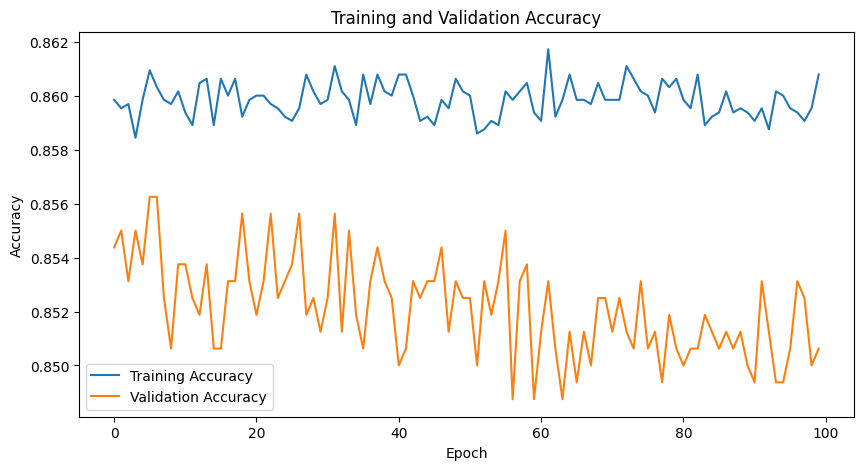

In [ ]:
#Accuracy
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

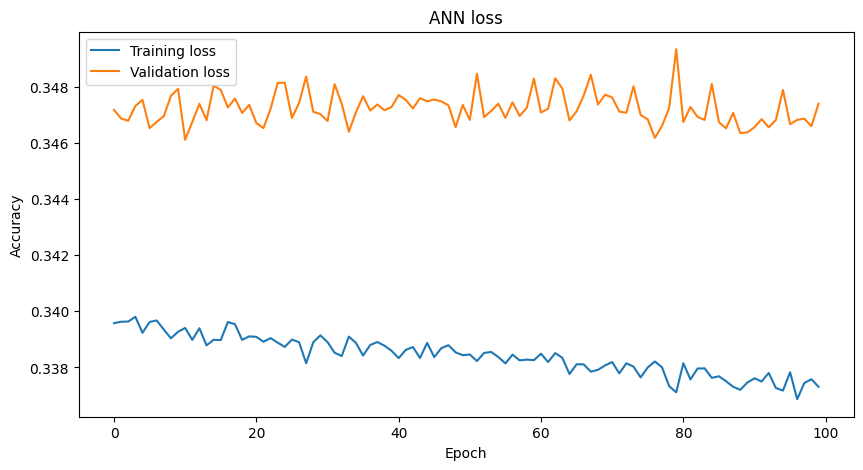

In [ ]:
#Loss Graph
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('ANN loss')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()